# Eleição 2026 comparada com 2022: o que é normal numa eleição brasileira?

Os notebooks 01 e 02 comparam cada indicador com um **modelo de acaso**. Este notebook usa uma régua mais concreta:
a **eleição presidencial de 2022**, com os mesmos testes, o mesmo código e os BUs oficiais do TSE. Um indicador de 2026
só merece atenção se fugir do que 2022 mostrou.

Também fecha três pontos que ficaram abertos nos notebooks 01 e 02:
1. **Por que o 2º dígito de Benford "reprova" quase todas as UFs?** (seção 2)
2. **Por que as seções que destoam do próprio local de votação pendem para um lado?** (seções 3 e 4)
3. **O padrão de comparecimento alto e de biometria é novo?** (seção 1)

Para ter os dados de 2022: `ELEICOES_ANO=2022 uv run baixar && ELEICOES_ANO=2022 uv run processar` (ficam em `data/2022`).
O perfil do eleitorado por seção vem de `uv run perfil`.

Todos os indicadores são medidos para **Lula**, o único candidato presente nos quatro turnos. No 2º turno, o que vale
para Lula vale com sinal trocado para o adversário; no 1º turno, "contra Lula" inclui todos os outros candidatos.

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from eleicoes_2026 import analise as A
from eleicoes_2026.config import PROCESSED

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.figsize": (11, 5), "figure.dpi": 110, "axes.titleweight": "bold"})
pd.options.display.float_format = "{:,.2f}".format

REF = "LULA"
FONTES = {"2022 1º turno": (1, 2022), "2022 2º turno": (2, 2022), "2026 1º turno": (1, 2026), "2026 2º turno": (2, 2026)}
E = {}
for nome, (t, ano) in FONTES.items():
    df = A.carregar_secoes(t, ano)
    if df is None:
        print(f"{nome}: não disponível")
    else:
        E[nome] = df
        print(f"{nome}: {len(df):,} seções")

2022 1º turno: 472,028 seções
2022 2º turno: 472,028 seções


2026 1º turno: 499,206 seções
2026 2º turno: não disponível


## 1. Painel de indicadores lado a lado
Cada linha é um teste dos notebooks 01 e 02. A coluna "2026 fora da faixa de 2022?" marca os indicadores em que
2026 fica fora do intervalo entre o menor e o maior valor dos dois turnos de 2022.

In [2]:
P = pd.DataFrame({nome: A.painel_anomalias(df, REF) for nome, df in E.items()})
c22 = [c for c in P.columns if c.startswith("2022")]
c26 = [c for c in P.columns if c.startswith("2026")]
lo, hi = P[c22].min(axis=1), P[c22].max(axis=1)
P["2026 fora da faixa de 2022?"] = [
    ", ".join(c.split()[1] + "ºT" for c in c26 if not lo[i] <= P.loc[i, c] <= hi[i]) or "não" for i in P.index
]
P

,2022 1º turno,2022 2º turno,2026 1º turno,2026 fora da faixa de 2022?
seções,"472,028.00","472,028.00","499,206.00",1ººT
% LULA,48.43,50.90,45.16,1ººT
violações aritméticas,0.00,0.00,0.00,não
seções |z|>5 no local,156.00,143.00,110.00,1ººT
|z|>5 esperado por acaso,0.42,0.78,0.52,não
|z|>5 a favor de LULA,123.00,110.00,77.00,1ººT
|z|>5 contra LULA,33.00,33.00,33.00,não
% dos |z|>5 na última seção do local,56.41,56.64,57.27,1ººT
% de todas as seções que são a última do local,19.60,19.60,18.97,1ººT
UFs reprovadas no 2BL (de 28),26.00,26.00,26.00,não


**Como ler.** Contagens de seções (|z|>5) dependem do tamanho e do equilíbrio da eleição, então diferenças moderadas
entre anos são esperadas. O que importa é a **forma**: direção dos extremos, concentração na última seção do local,
Benford observado vs. simulado, e o sinal dos efeitos dentro do município.

## 2. Benford: o teste reprova uma eleição sem fraude nenhuma
`A.simular_digitos` gera uma eleição artificial **sem nenhuma manipulação**: em cada seção, os votos de Lula são sorteados
com a proporção do município e a variação observada entre seções. Se a eleição simulada "reprova" tantas UFs quanto a
real, a reprovação mede só o tamanho da amostra e a forma da distribuição de votos, não fraude.

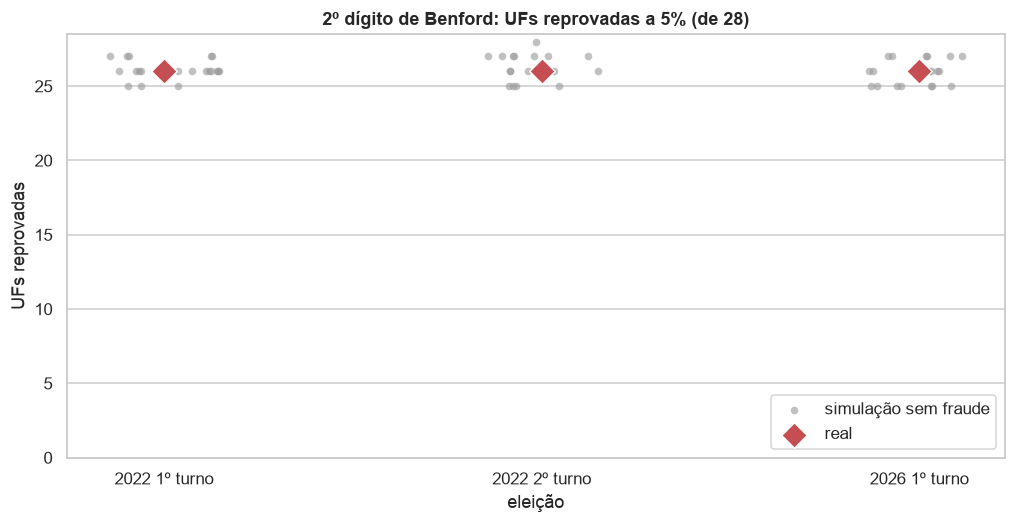

In [3]:
linhas = []
for nome, df in E.items():
    obs = sum(A.segundo_digito(g[REF])["p"] < .05 for _, g in df.groupby("uf", observed=True))
    sim = A.simular_digitos(df, REF, n_sim=20, seed=1)
    linhas += [{"eleição": nome, "fonte": "real", "UFs reprovadas": obs}]
    linhas += [{"eleição": nome, "fonte": "simulada sem fraude", "UFs reprovadas": v} for v in sim["reprova_2BL"]]
B = pd.DataFrame(linhas)
ax = sns.stripplot(data=B[B.fonte != "real"], x="eleição", y="UFs reprovadas", color="0.6", alpha=.6, jitter=.15, label="simulação sem fraude")
sns.scatterplot(data=B[B.fonte == "real"], x="eleição", y="UFs reprovadas", color="C3", s=140, marker="D", ax=ax, label="real", zorder=5)
h, l = ax.get_legend_handles_labels(); ax.legend(h[-2:], l[-2:], loc="lower right")
ax.set_ylim(0, 28.5); ax.set_title("2º dígito de Benford: UFs reprovadas a 5% (de 28)")
plt.show()

## 3. Seções que destoam do próprio local: a assimetria se repete
No notebook 02 (A10), as seções com |z|>5 em relação às outras seções do mesmo prédio pendiam contra o 1º colocado.
Abaixo, a mesma medida para Lula em todas as eleições: quantas seções extremas a favor e contra, e quantas delas são a
**última seção do local** (a de número mais alto, normalmente a mais nova).

In [4]:
linhas = []
for nome, df in E.items():
    t = A.desvio_no_local(df, REF).tabela.merge(df[["sec_id", "nr_secao", "comparecimento_pct"]], on="sec_id")
    g = t.groupby(A.CHAVE_LOCAL, observed=True)
    t["ultima"] = t["nr_secao"] == g["nr_secao"].transform("max")
    t["comp_rel"] = t["comparecimento_pct"] - g["comparecimento_pct"].transform("median")
    ext = t[t["z"].abs() > 5]
    for ult in (True, False):
        e = ext[ext["ultima"] == ult]
        linhas.append({"eleição": nome, "seção": "última do local" if ult else "demais",
                       "a favor": int((e["z"] > 0).sum()), "contra": int((e["z"] < 0).sum()),
                       "z médio de TODAS as seções": t.loc[t["ultima"] == ult, "z"].mean(),
                       "comparecimento vs. resto do local (p.p.)": t.loc[t["ultima"] == ult, "comp_rel"].median() * 100})
S = pd.DataFrame(linhas).set_index(["eleição", "seção"])
S

a favor  contra  z médio de TODAS as seções  \
eleição       seção                                                          
2022 1º turno última do local       79       9                        0.15   
              demais                44      24                       -0.02   
2022 2º turno última do local       69      12                        0.09   
              demais                41      21                       -0.01   
2026 1º turno última do local       43      20                       -0.03   
              demais                34      13                        0.01   

                               comparecimento vs. resto do local (p.p.)  
eleição       seção                                                      
2022 1º turno última do local                                      0.26  
              demais                                               0.00  
2022 2º turno última do local                                      0.00  
              demais                                               0.00  
2026 1º turno última do local                                      0.00  
              demais                                               0.00

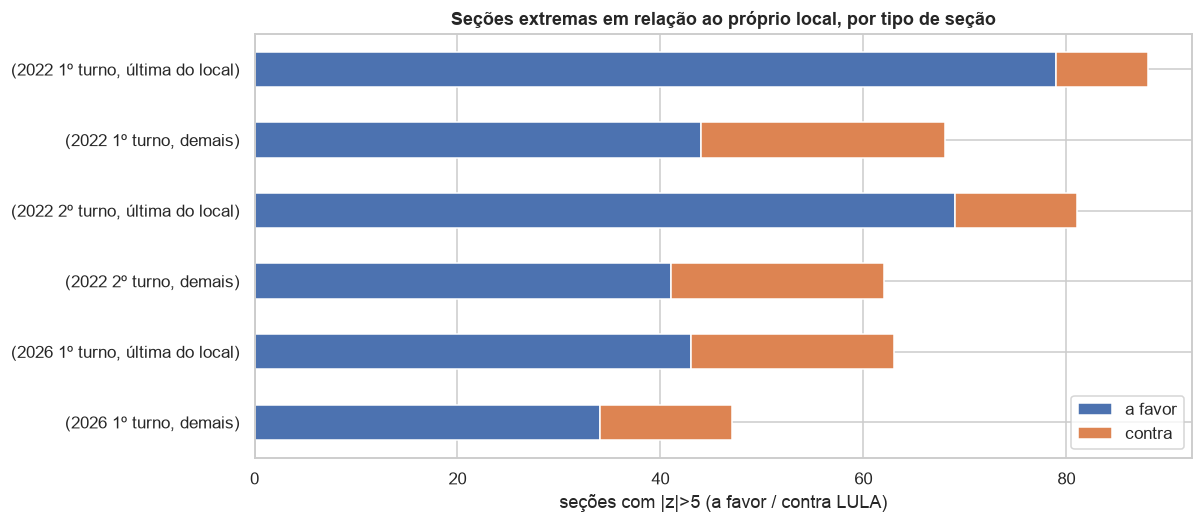

In [5]:
fig, ax = plt.subplots()
S[["a favor", "contra"]].plot.barh(stacked=True, ax=ax, color=["C0", "C1"])
ax.set_xlabel(f"seções com |z|>5 (a favor / contra {REF})"); ax.set_ylabel("")
ax.set_title("Seções extremas em relação ao próprio local, por tipo de seção")
ax.invert_yaxis(); plt.show()

**Leitura.** A assimetria aparece em 2022 e em 2026, na mesma direção, e se concentra na **última seção de cada local**.
Uma fraude não precisaria escolher justamente a seção mais nova do prédio. O padrão é compatível com a forma como o TSE
cria seções: quando um local enche, a seção nova recebe quem acabou de tirar ou transferir o título, um eleitorado mais
jovem e com mais estudantes que o resto do prédio. A seção 4 testa isso diretamente.

## 4. O perfil do eleitorado explica as seções extremas?
O TSE publica o **perfil do eleitorado de cada seção** (faixa etária, escolaridade). Se as seções extremas forem
explicadas por eleitorado diferente do resto do prédio, elas devem ter, em relação às vizinhas, mais (ou menos) jovens
e pessoas com ensino superior.

,"diferença p/ o resto do local, p.p.: 16_24","diferença p/ o resto do local, p.p.: 60_mais","diferença p/ o resto do local, p.p.: superior"
grupo,,,
demais seções,-0.71,-0.15,-0.11
|z|>5 a favor de LULA,14.32,-12.80,-1.13
|z|>5 contra LULA,19.19,-10.50,2.31


Seções com >10 p.p. mais eleitores de 16–24 anos que o resto do prédio: 7.1% das seções, mas 59% das seções |z|>5
   taxa de |z|>5: 18.1 por 10 mil entre elas vs 1.0 nas demais
   extremos que sobram fora desse grupo: 28 a favor de LULA, 13 contra (simetria: p = 0.028)


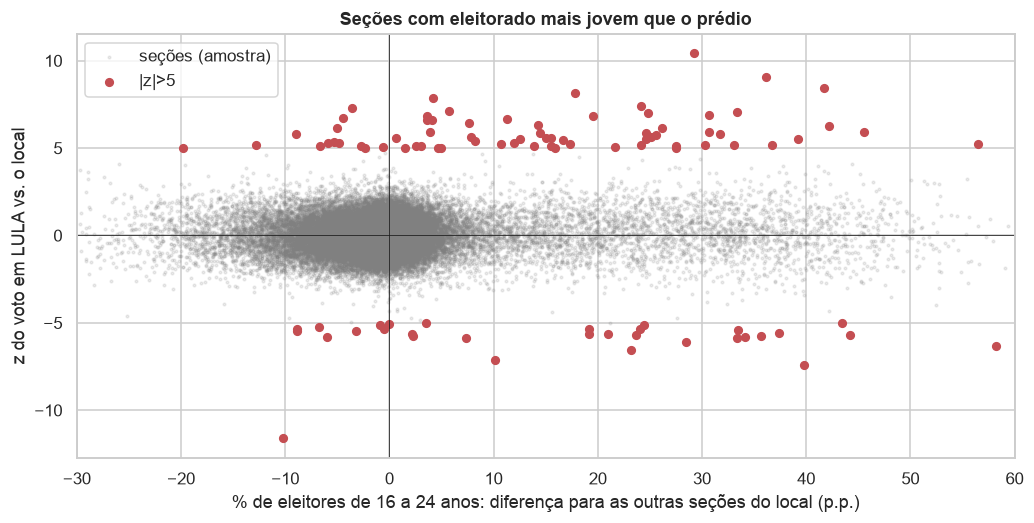

In [6]:
arq = PROCESSED / "perfil_secao.parquet"
if not arq.exists() or "2026 1º turno" not in E:
    print("Perfil por seção não disponível (rode `uv run perfil`).")
else:
    df = E["2026 1º turno"]
    perfil = pd.read_parquet(arq)
    t = A.desvio_no_local(df, REF).tabela.merge(df[["sec_id"] + A.CHAVE_SECAO], on=["sec_id"] + A.CHAVE_LOCAL[:3])
    t = t.merge(perfil, on=A.CHAVE_SECAO, how="left")
    for c in ("16_24", "60_mais", "superior"):
        t[f"pct_{c}"] = t[f"qt_{c}"] / t["qt_cadastro"] * 100
    g = t.groupby(A.CHAVE_LOCAL, observed=True)
    for c in ("pct_16_24", "pct_60_mais", "pct_superior"):  # diferença para as OUTRAS seções do local
        t[f"d_{c}"] = t[c] - (g[c].transform("sum") - t[c]) / (g[c].transform("size") - 1)
    t = t.dropna(subset=["d_pct_16_24", "d_pct_60_mais", "d_pct_superior"])
    t["grupo"] = np.select([t["z"] > 5, t["z"] < -5], [f"|z|>5 a favor de {REF}", f"|z|>5 contra {REF}"], "demais seções")
    display(t.groupby("grupo")[["d_pct_16_24", "d_pct_60_mais", "d_pct_superior"]].median()
            .rename(columns=lambda c: c.replace("d_pct_", "diferença p/ o resto do local, p.p.: ")))

    from scipy.stats import binomtest
    jovem = t["d_pct_16_24"] > 10
    extremo = t["z"].abs() > 5
    print(f"Seções com >10 p.p. mais eleitores de 16–24 anos que o resto do prédio: {jovem.mean():.1%} das seções, "
          f"mas {jovem[extremo].mean():.0%} das seções |z|>5")
    print(f"   taxa de |z|>5: {extremo[jovem].mean() * 1e4:.1f} por 10 mil entre elas vs {extremo[~jovem].mean() * 1e4:.1f} nas demais")
    resto = t[extremo & ~jovem]
    a_favor, contra = int((resto["z"] > 0).sum()), int((resto["z"] < 0).sum())
    print(f"   extremos que sobram fora desse grupo: {a_favor} a favor de {REF}, {contra} contra "
          f"(simetria: p = {binomtest(a_favor, a_favor + contra).pvalue:.2g})")

    fig, ax = plt.subplots()
    amostra = t.sample(min(len(t), 40000), random_state=0)
    ax.scatter(amostra["d_pct_16_24"], amostra["z"], s=3, alpha=.15, color="0.5", label="seções (amostra)")
    e = t[t["z"].abs() > 5]
    ax.scatter(e["d_pct_16_24"], e["z"], s=25, color="C3", label="|z|>5")
    ax.set_xlim(-30, 60); ax.axhline(0, color="k", lw=.5); ax.axvline(0, color="k", lw=.5)
    ax.set_xlabel("% de eleitores de 16 a 24 anos: diferença para as outras seções do local (p.p.)")
    ax.set_ylabel(f"z do voto em {REF} vs. o local"); ax.legend(); ax.set_title("Seções com eleitorado mais jovem que o prédio")
    plt.show()

**Leitura.** As seções extremas, **nos dois sentidos**, têm muito mais eleitores jovens e muito menos idosos que as outras
seções do mesmo prédio: são seções com outro eleitorado, não seções com votos alterados. O perfil explica por que elas
destoam, mas não o sentido: jovens de bairros diferentes votam diferente. A direção (mais extremos a favor de Lula) se repete
em 2022 e em 2026, inclusive no 1º turno de 2026, que Lula perdeu, o que é coerente com o voto jovem e não com um
favorecimento a quem venceu. Os extremos que sobram fora do grupo jovem ainda são mais do que o acaso explicaria; esses são
os candidatos a checagem manual (ata da mesa, BU impresso).

## 5. Resumo automático

In [7]:
fora = P[P["2026 fora da faixa de 2022?"] != "não"]
print("Indicadores em que 2026 sai da faixa dos dois turnos de 2022:")
print(fora[c22 + c26].round(2).to_string() if len(fora) else "   nenhum")
print("\nLembretes:")
print(" • 'Fora da faixa' com só dois pontos de referência é um critério frouxo: diferenças de tamanho e equilíbrio da disputa")
print("   mudam as contagens. Vale olhar a direção e o tamanho da diferença, não só o rótulo.")
print(" • Benford: compare o ponto real com a nuvem simulada (seção 2), não com 'reprovou / não reprovou'.")
print(" • Seções extremas: ver seções 3 e 4 sobre a última seção do local e o perfil do eleitorado.")

Indicadores em que 2026 sai da faixa dos dois turnos de 2022:
                                                                   2022 1º turno  2022 2º turno  2026 1º turno
seções                                                                472,028.00     472,028.00     499,206.00
% LULA                                                                     48.43          50.90          45.16
seções |z|>5 no local                                                     156.00         143.00         110.00
|z|>5 a favor de LULA                                                     123.00         110.00          77.00
% dos |z|>5 na última seção do local                                       56.41          56.64          57.27
% de todas as seções que são a última do local                             19.60          19.60          18.97
comparecimento ≥95%: efeito no voto (p.p., dentro do município)             8.36           6.12           5.64
+1 p.p. sem biometria: efeito no voto (p.p., dentr